In [13]:
#constants and imports

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t, binom


nu = 5
mu = 1
sigma = 0.01
n = 700

p = 0.975
q = 0.95

confidence interval: 1.02473051640241 1.0330980114810961
True quantile: 1.0257058183563632
Intervals containing the true quantile: 193/200
Empirical coverage: 96.500%


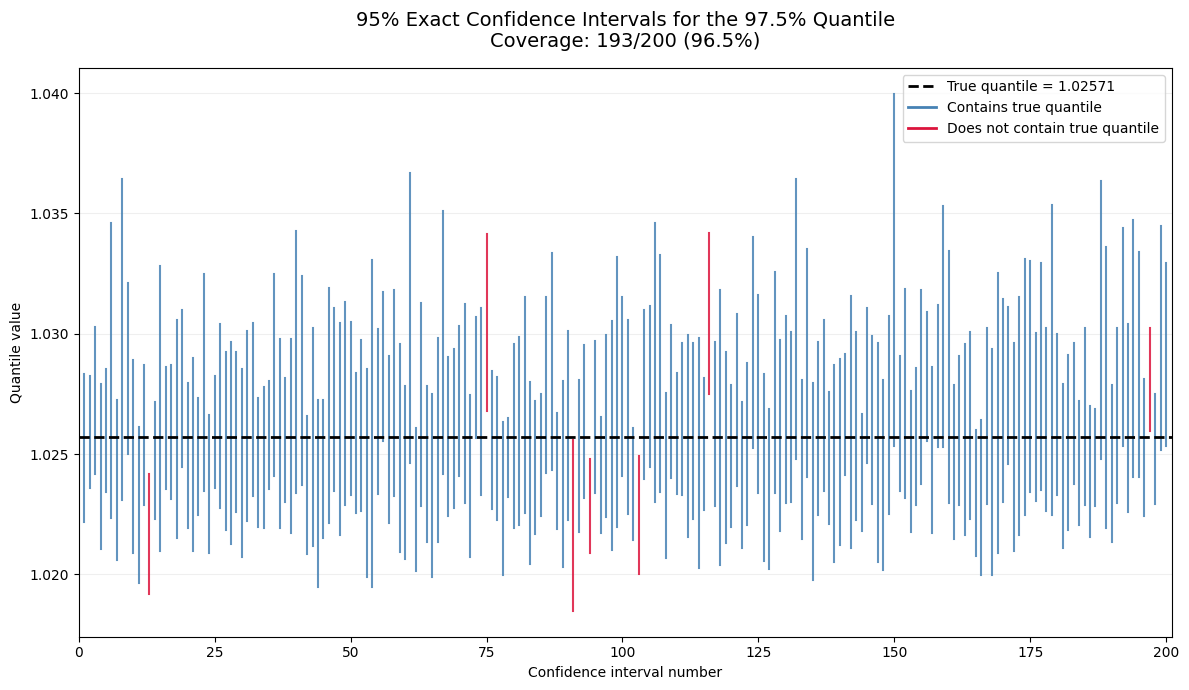

In [37]:
#t-distribution

np.random.seed(37)

theta_true = t.ppf(p, df=nu, loc=mu, scale=sigma)


def confint(k):
    x_lower_list = []
    x_upper_list = []
    for i in range(k):
        x_samples = t.rvs(df=nu, loc=mu, scale=sigma, size=n)
        x_sorted = np.sort(x_samples)

        #Find the smallest index y where P(Y>y) > a
        j1 = n - int(binom.ppf( (1+q)/2, n, 1-p ))
        j2 = n - int(binom.ppf( (1-q)/2, n, 1-p ))

        x_lower_list.append(x_sorted[j1-1])
        x_upper_list.append(x_sorted[j2-1])

        
    return x_lower_list, x_upper_list

#question A1(a)
x_lower_a, x_upper_a = confint(1)
x_lower_a = float(x_lower_a[0])
x_upper_a = float(x_upper_a[0])
print("confidence interval:", x_lower_a, x_upper_a)

k = 200
x_lower_b, x_upper_b = confint(k)
x_lower_b = np.array(x_lower_b)
x_upper_b = np.array(x_upper_b)

contains = (x_lower_b <= theta_true) & (theta_true <= x_upper_b)
count = 0
for c in contains:
    if c == True:
        count += 1
    else:
        pass

print(f"True quantile: {theta_true}")
print(f"Intervals containing the true quantile: {count}/{k}")
print(f"Empirical coverage: {count/k:.3%}")

fig, ax = plt.subplots(figsize=(12, 7))

for i in range(k):
    color = "steelblue" if contains[i] else "crimson"

    ax.plot(
        [i+1, i+1],
        [x_lower_b[i], x_upper_b[i]],
        color=color,
        linewidth=1.5,
        alpha=0.85
    )

# True quantile reference line
ax.axhline(theta_true, color="black", linestyle="--",
           linewidth=2, label=f"True quantile = {theta_true:.5f}")

# Legend
ax.plot([], [], color="steelblue", linewidth=2,
        label="Contains true quantile")
ax.plot([], [], color="crimson", linewidth=2,
        label="Does not contain true quantile")

ax.set_xlabel("Confidence interval number")
ax.set_ylabel("Quantile value")
ax.set_title(
    f"95% Exact Confidence Intervals for the 97.5% Quantile\n"
    f"Coverage: {count}/{k} ({count/k:.1%})",
    fontsize=14,
    pad=15
)

ax.set_xlim(0, k+1)
ax.grid(axis="y", alpha=0.2)
ax.legend(loc="best")

plt.tight_layout()
plt.show()
